In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Construyo una imagen de 5 filas y 5 columnas
gris = np.tile(np.linspace(0, 255, 5, dtype=np.uint8), (5, 1))

print("Shape:", gris.shape)
print("Tipo de dato:", gris.dtype)
print("Promedio:", gris.mean())
print(gris)

Shape: (5, 5)
Tipo de dato: uint8
Promedio: 127.2
[[  0  63 127 191 255]
 [  0  63 127 191 255]
 [  0  63 127 191 255]
 [  0  63 127 191 255]
 [  0  63 127 191 255]]


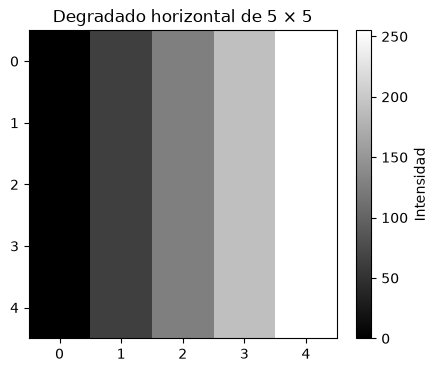

In [4]:
plt.figure(figsize=(5, 4))
plt.imshow(gris, cmap="gray", vmin=0, vmax=255)
plt.colorbar(label="Intensidad")
plt.title("Degradado horizontal de 5 × 5")

plt.savefig("gris_tema6.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
recorte = gris[:, -2:]
print(recorte)

[[191 255]
 [191 255]
 [191 255]
 [191 255]
 [191 255]]


(4, 4, 3)
Pixel [0,0]: [255   0   0]
Pixel [0,3]: [  0 255   0]


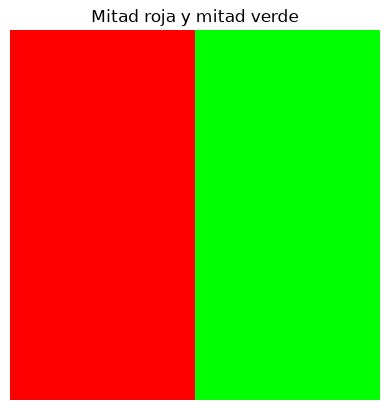

In [6]:
rgb = np.zeros((4, 4, 3), dtype=np.uint8)

rgb[:, 0:2] = [255, 0, 0]   # Mitad izquierda: rojo
rgb[:, 2:4] = [0, 255, 0]   # Mitad derecha: verde

print(rgb.shape)
print("Pixel [0,0]:", rgb[0, 0])
print("Pixel [0,3]:", rgb[0, 3])

plt.imshow(rgb)
plt.title("Mitad roja y mitad verde")
plt.axis("off")
plt.show()

Canal rojo:
[[255 255   0   0]
 [255 255   0   0]
 [255 255   0   0]
 [255 255   0   0]]

Canal verde:
[[  0   0 255 255]
 [  0   0 255 255]
 [  0   0 255 255]
 [  0   0 255 255]]

Canal azul:
[[0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]]


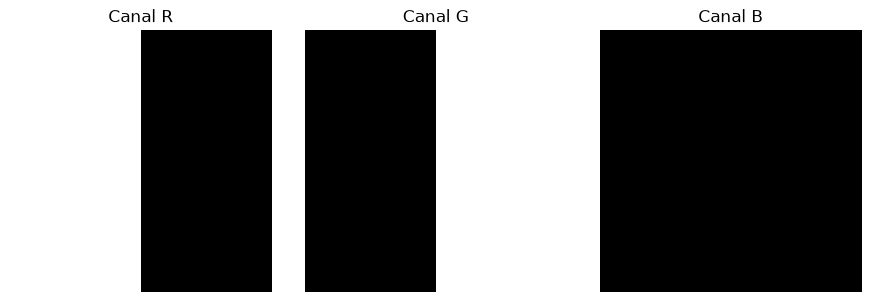

In [7]:
canal_r = rgb[:, :, 0]
canal_g = rgb[:, :, 1]
canal_b = rgb[:, :, 2]

print("Canal rojo:")
print(canal_r)

print("\nCanal verde:")
print(canal_g)

print("\nCanal azul:")
print(canal_b)

fig, ejes = plt.subplots(1, 3, figsize=(9, 3))

for eje, canal, titulo in zip(
    ejes,
    [canal_r, canal_g, canal_b],
    ["Canal R", "Canal G", "Canal B"]
):
    eje.imshow(canal, cmap="gray", vmin=0, vmax=255)
    eje.set_title(titulo)
    eje.axis("off")

plt.tight_layout()
plt.show()

In [8]:
gris_promedio = rgb.mean(axis=2).astype(np.uint8)

gris_luminosidad = (
    0.299 * rgb[:, :, 0].astype(float)
    + 0.587 * rgb[:, :, 1].astype(float)
    + 0.114 * rgb[:, :, 2].astype(float)
).astype(np.uint8)

print("Promedio simple:")
print(gris_promedio)

print("\nLuminosidad ponderada:")
print(gris_luminosidad)

Promedio simple:
[[85 85 85 85]
 [85 85 85 85]
 [85 85 85 85]
 [85 85 85 85]]

Luminosidad ponderada:
[[ 76  76 149 149]
 [ 76  76 149 149]
 [ 76  76 149 149]
 [ 76  76 149 149]]


[[  0   0 255 255]
 [  0   0 255 255]
 [  0   0 255 255]
 [  0   0 255 255]]


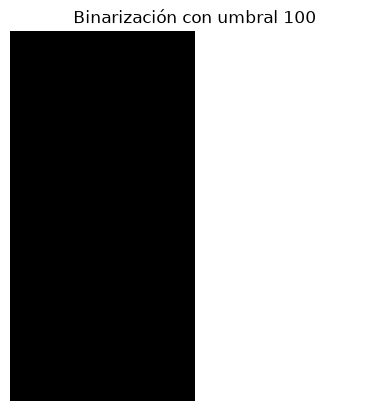

In [9]:
umbral = 100
binaria = (gris_luminosidad >= umbral).astype(np.uint8) * 255

print(binaria)

plt.imshow(binaria, cmap="gray", vmin=0, vmax=255)
plt.title(f"Binarización con umbral {umbral}")
plt.axis("off")
plt.show()